# SafeRoute crime-risk model: explore, train, infer

This notebook walks through the whole risk model end to end:

1. **Explore** the LAPD incidents we downloaded for the USC area (`data/crime.db`)
2. **Train** the XGBoost cell × hour model (and the sklearn comparison) with a time-based split
3. **Evaluate** it on the full 2023 grid, with calibration and SHAP
4. **Infer** with `score_cell` / `explain_cell`, the same functions the Flask API calls

It reuses the code in `algorithm/`, so anything you change in the scripts shows up here.
Run it from the `algorithm/` folder with **Kernel → Restart & Run All**. It takes about a minute.

In [1]:
import sys, sqlite3, datetime as dt
from pathlib import Path

# Make `import algorithm...` work whether the kernel starts in algorithm/ or the repo root.
here = Path.cwd().resolve()
repo_root = here.parent if here.name == "algorithm" else here
sys.path.insert(0, str(repo_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection
import h3

from algorithm.common import config, geo
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("repo root:", repo_root)
print("database :", config.DB_PATH)

repo root: /home/user/repo
database : /home/user/repo/algorithm/data/crime.db


## 1. Data

If `data/crime.db` is missing, this cell downloads it from the LA Open Data API (about a minute).

In [2]:
if not config.DB_PATH.exists():
    from algorithm.data import ingest_crime
    ingest_crime.main()

con = sqlite3.connect(config.DB_PATH)
inc = pd.read_sql("SELECT * FROM incidents", con, parse_dates=["date_occ"])
con.close()
inc["year"] = inc.date_occ.dt.year
inc["weekday"] = inc.date_occ.dt.day_of_week
print(f"{len(inc):,} incidents  |  {inc.date_occ.min():%Y-%m-%d} to {inc.date_occ.max():%Y-%m-%d}  |  {inc.cell.nunique()} H3 cells")
inc.head()

37,462 incidents  |  2020-01-01 to 2024-12-30  |  147 H3 cells


,dr_no,date_occ,time_occ,hour,lat,lon,crm_cd,crm_cd_desc,weapon_used_cd,part_1_2,cell,tier,year,weekday
0,010304468,2020-01-08,2230,22,34.0141,-118.2978,624,BATTERY - SIMPLE ASSAULT,400,2,8929a1d648fffff,violent,2020,2
1,200100562,2020-01-25,240,2,34.0352,-118.2654,860,BATTERY WITH SEXUAL CONTACT,400,2,8929a1d6673ffff,violent,2020,5
2,200100634,2020-02-26,1430,14,34.0320,-118.2667,480,BIKE - STOLEN,NaN,1,8929a1d6603ffff,property,2020,2
3,200100711,2020-03-23,1300,13,34.0395,-118.2656,121,"RAPE, FORCIBLE",400,1,8929a1d6663ffff,violent,2020,0
4,200100813,2020-05-25,2100,21,34.0395,-118.2656,236,INTIMATE PARTNER - AGGRAVATED ASSAULT,503,1,8929a1d6663ffff,violent,2020,0


### Volume over time

Note the drop from March 2024: that is LAPD's switch to NIBRS reporting, not a real fall in crime. It's why we train on 2020–2022 and test on 2023.

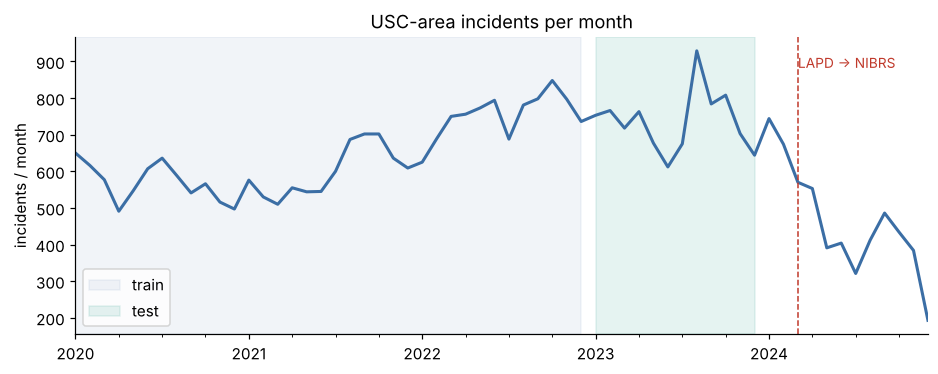

year,2020,2021,2022,2023,2024
incidents,6833,7196,9035,8832,5566


In [3]:
monthly = inc.set_index("date_occ").resample("MS").size()
fig, ax = plt.subplots(figsize=(10, 3.5))
monthly.plot(ax=ax, color="#3b6ea5", lw=2)
ax.axvspan(pd.Timestamp("2020-01-01"), pd.Timestamp("2022-12-31"), color="#3b6ea5", alpha=0.07, label="train")
ax.axvspan(pd.Timestamp("2023-01-01"), pd.Timestamp("2023-12-31"), color="#2a9d8f", alpha=0.12, label="test")
ax.axvline(pd.Timestamp("2024-03-01"), color="#c0392b", ls="--", lw=1)
ax.text(pd.Timestamp("2024-03-15"), monthly.max() * 0.95, "LAPD → NIBRS", color="#c0392b", fontsize=9)
ax.set_ylabel("incidents / month"); ax.set_xlabel(""); ax.legend(loc="lower left")
ax.set_title("USC-area incidents per month")
plt.show()
inc.groupby("year").size().rename("incidents").to_frame().T

### Severity mix and most common crimes

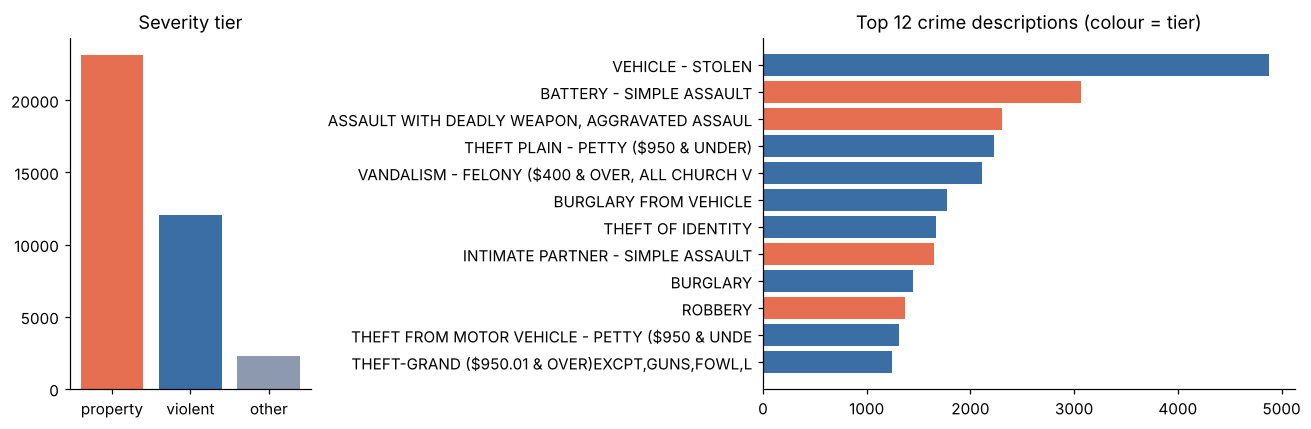

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1, 2.2]})
tier = inc.tier.value_counts()
axes[0].bar(tier.index, tier.values, color=["#e76f51", "#3b6ea5", "#8d99ae"])
axes[0].set_title("Severity tier")
top = inc.crm_cd_desc.value_counts().head(12)[::-1]
colors = inc.drop_duplicates("crm_cd_desc").set_index("crm_cd_desc").loc[top.index, "tier"].map(
    {"violent": "#e76f51", "property": "#3b6ea5", "other": "#8d99ae"})
axes[1].barh([s[:45] for s in top.index], top.values, color=colors)
axes[1].set_title("Top 12 crime descriptions (colour = tier)")
plt.tight_layout(); plt.show()

### When does it happen?

The spike at noon is partly an artifact: LAPD records `time_occ = 1200` when the time is unknown.

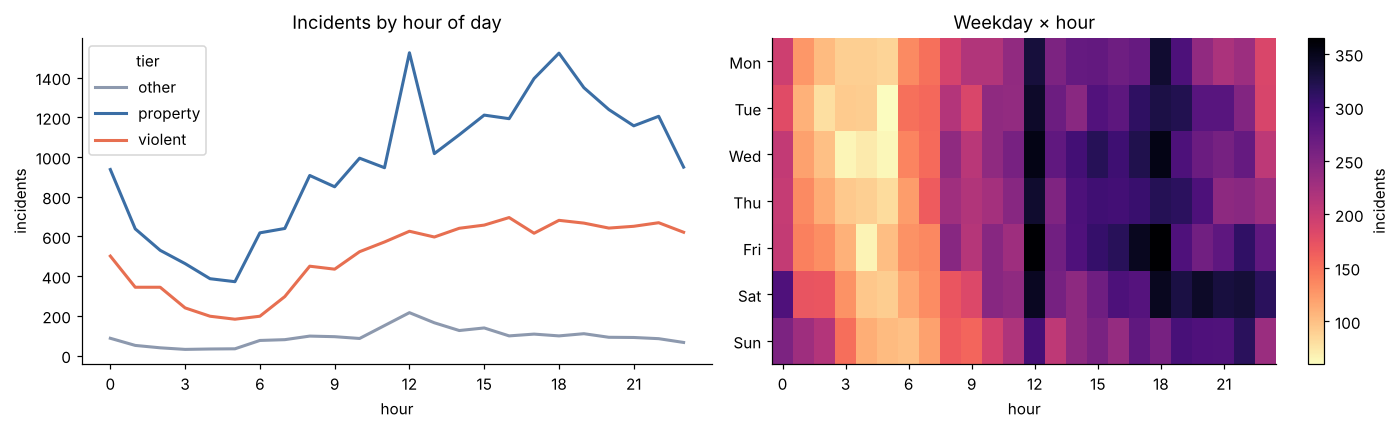

share at exactly 12:00: 3.0%


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
by_hour = inc.groupby(["hour", "tier"]).size().unstack(fill_value=0)
by_hour.plot(ax=axes[0], color={"violent": "#e76f51", "property": "#3b6ea5", "other": "#8d99ae"}, lw=2)
axes[0].set_xticks(range(0, 24, 3)); axes[0].set_title("Incidents by hour of day"); axes[0].set_ylabel("incidents")

grid = inc.groupby(["weekday", "hour"]).size().unstack(fill_value=0)
im = axes[1].imshow(grid, aspect="auto", cmap="magma_r")
axes[1].set_yticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
axes[1].set_xticks(range(0, 24, 3)); axes[1].set_xlabel("hour"); axes[1].set_title("Weekday × hour")
plt.colorbar(im, ax=axes[1], label="incidents")
plt.tight_layout(); plt.show()
print("share at exactly 12:00:", f"{(inc.time_occ == 1200).mean():.1%}")

### After dark

We compute civil dawn/dusk for LA on each date with `astral`.

In [6]:
inc["is_dark"] = [geo.is_dark(d.date(), h) for d, h in zip(inc.date_occ, inc.hour)]
days = pd.date_range(config.DATA_START, config.DATA_END)
dark_hours = np.mean([geo.is_dark(d.date(), h) for d in days[::7] for h in range(24)])
pd.DataFrame({
    "share of all hours that are dark": [dark_hours],
    "share of incidents after dark": [inc.is_dark.mean()],
    "share of VIOLENT incidents after dark": [inc.loc[inc.tier == "violent", "is_dark"].mean()],
}).T.rename(columns={0: "value"}).style.format("{:.1%}")

,value
share of all hours that are dark,45.2%
share of incidents after dark,40.1%
share of VIOLENT incidents after dark,41.6%


### Where? Incidents per H3 cell (res 9, ~175 m)

Blue dots are the **placeholder** blue-light phone points from `common/geo.py`.

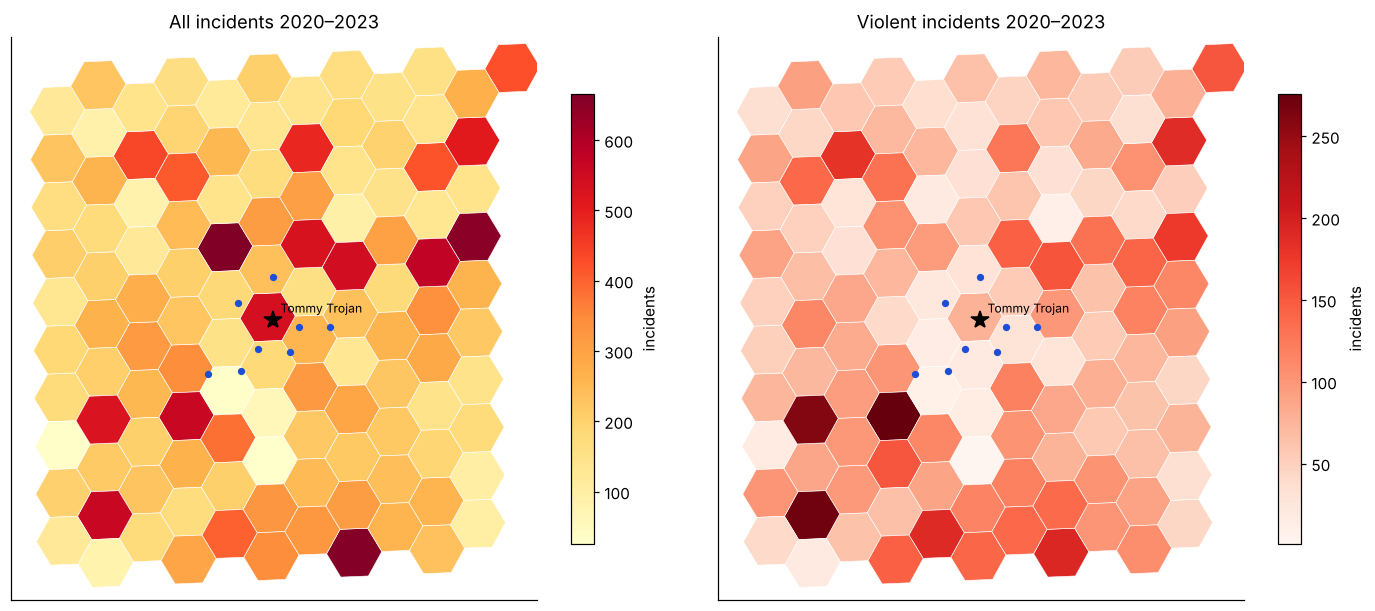

116 cells in the model area; busiest cell has 666 incidents, 0 cells have none


In [7]:
def hexmap(ax, values: dict, title, cmap="YlOrRd", vmin=None, vmax=None, label=""):
    cells = list(values)
    polys = [[(lng, lat) for lat, lng in h3.cell_to_boundary(c)] for c in cells]
    pc = PolyCollection(polys, array=np.array([values[c] for c in cells], dtype=float),
                        cmap=cmap, edgecolor="white", linewidth=0.4)
    if vmin is not None: pc.set_clim(vmin, vmax)
    ax.add_collection(pc)
    s, w, n, e = config.BBOX
    ax.set_xlim(w - 0.002, e + 0.002); ax.set_ylim(s - 0.002, n + 0.002)
    ax.set_aspect(1 / np.cos(np.radians(34.02)))
    ax.plot(config.CENTER[1], config.CENTER[0], marker="*", color="black", ms=12)
    ax.annotate("Tommy Trojan", (config.CENTER[1], config.CENTER[0]), xytext=(5, 5), textcoords="offset points", fontsize=8)
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])
    plt.colorbar(pc, ax=ax, shrink=0.8, label=label)

counts = inc[inc.year <= 2023].groupby("cell").size()
area = {c: counts.get(c, 0) for c in geo.area_cells()}
violent = inc[(inc.year <= 2023) & (inc.tier == "violent")].groupby("cell").size()
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
hexmap(axes[0], area, "All incidents 2020–2023", label="incidents")
hexmap(axes[1], {c: violent.get(c, 0) for c in geo.area_cells()}, "Violent incidents 2020–2023", cmap="Reds", label="incidents")
for ax in axes:
    ph = geo.bluelight_phones()
    ax.scatter([p[1] for p in ph], [p[0] for p in ph], s=14, color="#1d4ed8", zorder=3)
plt.tight_layout(); plt.show()
print(f"{len(area)} cells in the model area; busiest cell has {max(area.values())} incidents, "
      f"{sum(v == 0 for v in area.values())} cells have none")

## 2. Build the training frame

Each row is one **(H3 cell, date, hour)**. Target = at least one incident in that cell in that hour.
All history features use only incidents from **before** the row's date, so nothing leaks from the future.
Training keeps every positive plus 15 random negatives each. We undo that sampling later (prior correction) so the outputs are real probabilities.

In [8]:
from algorithm.features.build_dataset import History, FEATURES

hist = History()
frame, neg_rate, base_rate = hist.training_frame(kind="any")
vday = hist.day_index(dt.date.fromisoformat(config.VALID_START))
tr, va = frame[frame.day < vday], frame[frame.day >= vday]
print(f"training frame: {len(frame):,} rows, {int(frame.y.sum()):,} positives")
print(f"true base rate: {base_rate:.3%} of cell-hours have an incident; negatives kept at rate {neg_rate:.3f}")
print(f"train {len(tr):,} rows (to {config.VALID_START}), early-stopping slice {len(va):,} rows")
frame[FEATURES + ["y"]].sample(5, random_state=0)

training frame: 289,216 rows, 18,076 positives
true base rate: 0.645% of cell-hours have an incident; negatives kept at rate 0.097
train 236,035 rows (to 2022-07-01), early-stopping slice 53,181 rows


,hour,weekday,month,season,is_weekend,is_dark,cell_lat,cell_lon,dist_bluelight_m,cell_7d,...,cell_sev_90d,cell_violent_90d,cell_hourband_365d,cell_rate_all,cell_hourband_rate_all,nb1_30d,nb2_30d,nb1_90d,area_7d,y
79784,18.0,0.0,11.0,3.0,0.0,1.0,34.022610,-118.285530,252.947205,0.0,...,6.2,4.0,11.0,50.143768,12.827477,6.0,50.0,16.0,108.0,0
69551,22.0,4.0,6.0,2.0,0.0,1.0,34.022137,-118.299385,903.266479,0.0,...,6.0,2.0,3.0,41.242939,6.186440,23.0,34.0,59.0,142.0,0
282117,0.0,4.0,9.0,3.0,0.0,1.0,34.007820,-118.281784,1350.908447,0.0,...,11.0,8.0,9.0,69.458954,12.257463,39.0,34.0,132.0,100.0,0
169711,8.0,3.0,12.0,0.0,0.0,0.0,34.034798,-118.268425,1803.675781,2.0,...,27.4,19.0,15.0,127.905983,15.598290,18.0,32.0,62.0,104.0,0
142453,20.0,0.0,2.0,0.0,0.0,1.0,34.012672,-118.285339,728.654907,0.0,...,0.0,0.0,0.0,2.758186,0.000000,25.0,67.0,58.0,119.0,0


In [9]:
frame.groupby("y")[["cell_30d", "cell_hourband_365d", "cell_rate_all", "nb1_30d", "is_dark", "dist_bluelight_m"]].mean().T.rename(
    columns={0: "no incident", 1: "incident"}).round(2)

y,no incident,incident
cell_30d,4.900000,6.790000
cell_hourband_365d,6.380000,9.860000
cell_rate_all,54.779999,70.989998
nb1_30d,27.209999,28.490000
is_dark,0.450000,0.400000
dist_bluelight_m,1060.060059,1049.020020


## 3. Train

XGBoost with early stopping (same settings as `models/train_xgb.py`), and sklearn's `GradientBoostingClassifier` for comparison.

XGBoost: best iteration 235, 4.3s


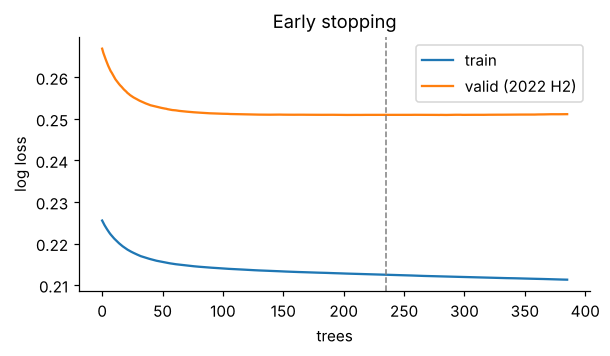

sklearn GBC: 25.4s on 80,000 rows


In [10]:
import time
import xgboost as xgb
from sklearn.ensemble import GradientBoostingClassifier

t0 = time.time()
model = xgb.XGBClassifier(
    n_estimators=2000, learning_rate=0.03, max_depth=4, min_child_weight=20,
    subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0, tree_method="hist",
    eval_metric="logloss", early_stopping_rounds=150, random_state=config.SEED, n_jobs=-1)
model.fit(tr[FEATURES], tr.y, eval_set=[(tr[FEATURES], tr.y), (va[FEATURES], va.y)], verbose=False)
print(f"XGBoost: best iteration {model.best_iteration}, {time.time() - t0:.1f}s")

ev = model.evals_result()
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(ev["validation_0"]["logloss"], label="train"); ax.plot(ev["validation_1"]["logloss"], label="valid (2022 H2)")
ax.axvline(model.best_iteration, color="gray", ls="--", lw=1); ax.set_xlabel("trees"); ax.set_ylabel("log loss"); ax.legend()
ax.set_title("Early stopping"); plt.show()

t1 = time.time()
sub = tr.sample(n=min(len(tr), 80_000), random_state=config.SEED)
gbc = GradientBoostingClassifier(n_estimators=200, max_depth=3, learning_rate=0.1, subsample=0.8, random_state=config.SEED)
gbc.fit(sub[FEATURES], sub.y)
print(f"sklearn GBC: {time.time() - t1:.1f}s on {len(sub):,} rows")

## 4. Evaluate on the full 2023 grid

Every area cell × every hour × every day of 2023, about 1M rows, none seen in training.

In [11]:
from sklearn.metrics import roc_curve, precision_recall_curve
from sklearn.calibration import calibration_curve
from algorithm.models.train_xgb import prior_correct, evaluate
# train_xgb switches matplotlib to a file backend on import; switch back to inline
%matplotlib inline

test = hist.frame_for_range(config.TEST_START, config.TEST_END)
y = test.y.to_numpy()
p_xgb = prior_correct(model.predict_proba(test[FEATURES])[:, 1], neg_rate)
p_gbc = prior_correct(gbc.predict_proba(test[FEATURES])[:, 1], neg_rate)
p_base = test.cell_hourband_365d.to_numpy() + 1e-3 * test.cell_90d.to_numpy()
print(f"{len(test):,} cell-hours, {int(y.sum()):,} with an incident\n")
results = pd.DataFrame({
    "XGBoost": evaluate(y, p_xgb, "XGBoost"),
    "sklearn GBC": evaluate(y, p_gbc, "sklearn GradientBoosting"),
    "Baseline (past-year count)": evaluate(y, p_base, "Baseline (past-year count)", probabilistic=False),
}).T[["auc", "pr_auc", "top10pct_capture", "brier", "mean_pred", "base_rate"]]
results.style.format("{:.4f}", na_rep="–")

1,016,160 cell-hours, 7,438 with an incident



  XGBoost                      AUC 0.686  PR-AUC 0.0169  (base 0.0073)  top-10% capture 27.9%


  sklearn GradientBoosting     AUC 0.669  PR-AUC 0.0139  (base 0.0073)  top-10% capture 24.0%
  Baseline (past-year count)   AUC 0.674  PR-AUC 0.0175  (base 0.0073)  top-10% capture 27.1%


,auc,pr_auc,top10pct_capture,brier,mean_pred,base_rate
XGBoost,0.6864,0.0169,0.2791,0.0072,0.0077,0.0073
sklearn GBC,0.6693,0.0139,0.2398,0.0094,0.0132,0.0073
Baseline (past-year count),0.6738,0.0175,0.2714,–,–,0.0073


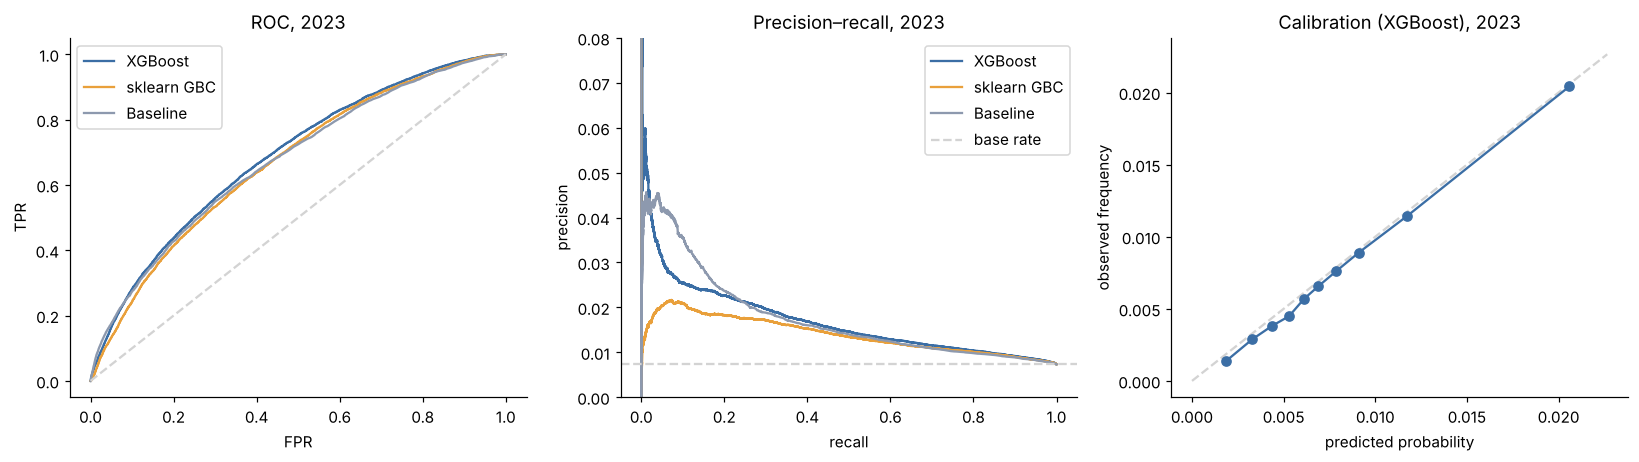

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for name, p, c in [("XGBoost", p_xgb, "#3b6ea5"), ("sklearn GBC", p_gbc, "#e9a03b"), ("Baseline", p_base, "#8d99ae")]:
    fpr, tpr, _ = roc_curve(y, p); axes[0].plot(fpr, tpr, label=name, color=c)
    pr, rc, _ = precision_recall_curve(y, p); axes[1].plot(rc, pr, label=name, color=c)
axes[0].plot([0, 1], [0, 1], ls="--", c="lightgray"); axes[0].set(title="ROC, 2023", xlabel="FPR", ylabel="TPR"); axes[0].legend()
axes[1].axhline(y.mean(), ls="--", c="lightgray", label="base rate"); axes[1].set(title="Precision–recall, 2023", xlabel="recall", ylabel="precision", ylim=(0, 0.08)); axes[1].legend()
frac, mean_pred = calibration_curve(y, p_xgb, n_bins=10, strategy="quantile")
hi = max(frac.max(), mean_pred.max()) * 1.1
axes[2].plot([0, hi], [0, hi], ls="--", c="lightgray"); axes[2].plot(mean_pred, frac, marker="o", color="#3b6ea5")
axes[2].set(title="Calibration (XGBoost), 2023", xlabel="predicted probability", ylabel="observed frequency")
plt.tight_layout(); plt.show()

### Heatmap-level check

The app shows risk per cell per hour of day. Averaged over 2023, does the model's ranking of those slots match what happened?

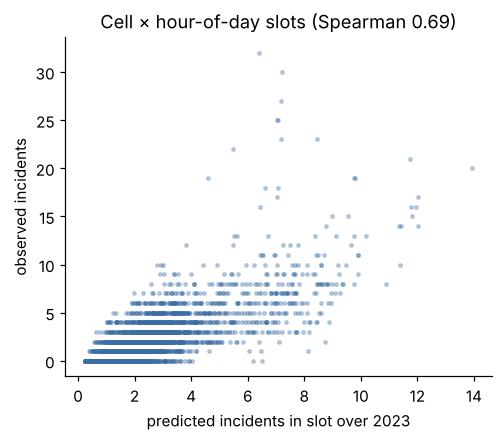

In [13]:
slot = pd.DataFrame({"cell": test.cell_idx, "hour": test.hour, "pred": p_xgb, "obs": y}).groupby(["cell", "hour"]).agg(pred=("pred", "mean"), obs=("obs", "sum"))
rho = slot.pred.corr(slot.obs, method="spearman")
fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(slot.pred * 365, slot.obs, s=5, alpha=0.3, color="#3b6ea5")
ax.set(xlabel="predicted incidents in slot over 2023", ylabel="observed incidents", title=f"Cell × hour-of-day slots (Spearman {rho:.2f})")
plt.show()

### Why does the model say what it says? (SHAP)

Each dot is one cell-hour. Red = high feature value; right = pushes risk up.

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


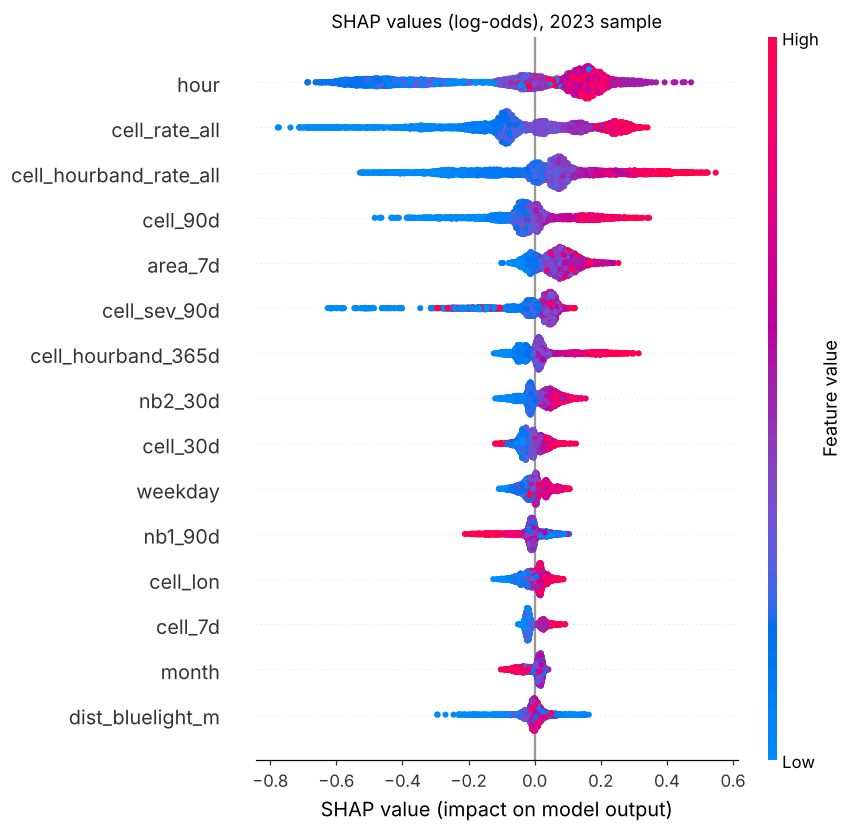

,mean |SHAP|
hour,0.2120
cell_rate_all,0.1515
cell_hourband_rate_all,0.1404
cell_90d,0.0710
area_7d,0.0692
cell_sev_90d,0.0572
cell_hourband_365d,0.0488
nb2_30d,0.0402
cell_30d,0.0276
weekday,0.0268


In [14]:
import shap
sample = test.sample(5000, random_state=config.SEED)[FEATURES]
contribs = model.get_booster().predict(xgb.DMatrix(sample), pred_contribs=True)[:, :-1]
shap.summary_plot(contribs, sample, max_display=15, show=False)
plt.title("SHAP values (log-odds), 2023 sample"); plt.show()
pd.Series(np.abs(contribs).mean(0), index=FEATURES).sort_values(ascending=False).head(10).rename("mean |SHAP|").to_frame().round(4)

## 5. Inference with the saved model

`score_cell` and `explain_cell` load the model saved by `python -m algorithm.models.train_xgb`
(`models/artifacts/xgb_risk.ubj`), which uses the same settings as above. These are the functions the Flask API calls.

- **risk** (0–1): percentile of this cell-hour among all USC-area cell-hours in 2023. Use it for colour and routing.
- **prob**: calibrated chance that at least one incident is reported in that cell in that hour.

In [15]:
from algorithm.scoring.score import score_cell, explain_cell, build_cache

TODAY = dt.date(2026, 11, 14)
places = {
    "Tommy Trojan": (34.0206, -118.2854),
    "USC Village": (34.0254, -118.2851),
    "Exposition Park / Natural History Museum": (34.0170, -118.2887),
    "Figueroa & Adams": (34.0328, -118.2747),
    "Vermont & Jefferson": (34.0256, -118.2917),
}
rows = []
for name, (lat, lng) in places.items():
    cell = h3.latlng_to_cell(lat, lng, config.H3_RES)
    rows.append({"place": name, "cell": cell, **{f"{h:02d}:00": score_cell(cell, h, TODAY) for h in (2, 9, 14, 18, 22)}})
pd.DataFrame(rows).set_index("place").style.format("{:.2f}", subset=pd.IndexSlice[:, ["02:00", "09:00", "14:00", "18:00", "22:00"]]).background_gradient(cmap="YlOrRd", axis=None, vmin=0, vmax=1, subset=pd.IndexSlice[:, ["02:00", "09:00", "14:00", "18:00", "22:00"]])

,cell,02:00,09:00,14:00,18:00,22:00
place,,,,,,
Tommy Trojan,8929a1d6457ffff,0.06,0.29,0.51,0.75,0.62
USC Village,8929a1d647bffff,0.12,0.33,0.76,0.83,0.59
Exposition Park / Natural History Museum,8929a1d641bffff,0.01,0.03,0.03,0.06,0.02
Figueroa & Adams,8929a1d66abffff,0.23,0.29,0.42,0.47,0.49
Vermont & Jefferson,8929a1d6477ffff,0.28,0.32,0.58,0.72,0.68


### Explain one score

`effect` is the SHAP contribution in log-odds: positive raises risk, negative lowers it.

In [16]:
cell = h3.latlng_to_cell(*places["Figueroa & Adams"], config.H3_RES)
ex = explain_cell(cell, 22, TODAY, top_k=6)
print(f"{ex['cell']} at {ex['hour']}:00 on {ex['date']}: risk {ex['risk']:.2f}, prob {ex['prob']:.2%} (history as of {ex['history_as_of']})")
pd.DataFrame(ex["factors"])[["label", "value", "effect"]]

8929a1d66abffff at 22:00 on 2026-11-14: risk 0.49, prob 0.64% (history as of 2023-12-31)


,label,value,effect
0,time of day,22.000,0.1958
1,long-run incident rate here,37.225,-0.0902
2,"incidents 2 blocks away, 30 days",69.000,0.0466
3,"incidents here at this hour, past year",2.000,-0.0416
4,"area-wide incidents, last 7 days",128.000,-0.0410
5,"incidents here, last 90 days",7.000,-0.0404


### What-if: override a feature

`context_features` lets the API pass live context, for example a phone that turned out to be nearer, or forcing darkness.

In [17]:
cell = h3.latlng_to_cell(*places["USC Village"], config.H3_RES)
pd.DataFrame({
    "as-is": [score_cell(cell, 17, TODAY)],
    "blue-light phone 50 m away": [score_cell(cell, 17, TODAY, {"dist_bluelight_m": 50})],
    "blue-light phone 1.5 km away": [score_cell(cell, 17, TODAY, {"dist_bluelight_m": 1500})],
    "is_dark forced on": [score_cell(cell, 17, TODAY, {"is_dark": 1})],
}, index=["USC Village, 5 PM"]).round(3)

,as-is,blue-light phone 50 m away,blue-light phone 1.5 km away,is_dark forced on
"USC Village, 5 PM",0.809,0.809,0.845,0.809


### The heatmap the app will show

`build_cache` scores every cell for all 24 hours in one call (about a second). This is what `scoring/cache/risk_cache.json` holds.

116 cells × 24 hours in 0.1s


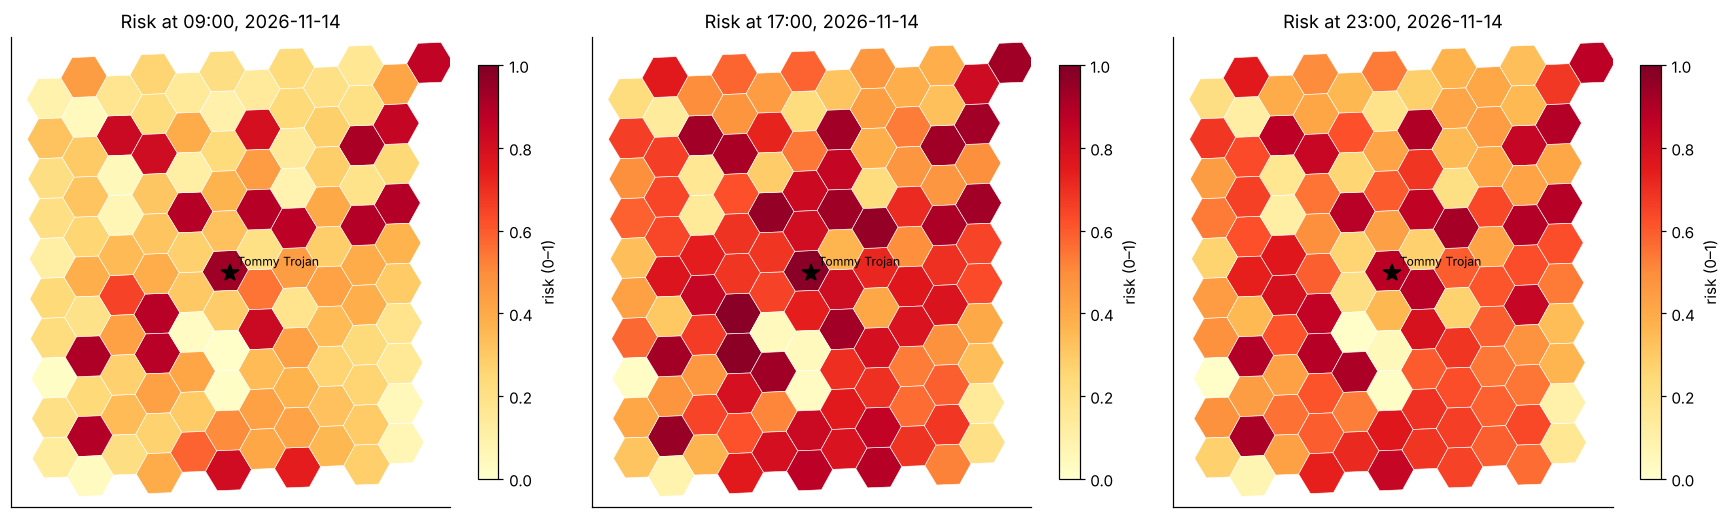

In [18]:
t0 = time.time()
cache = build_cache(TODAY)
print(f"{len(cache['cells'])} cells × 24 hours in {time.time() - t0:.1f}s")
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, h in zip(axes, (9, 17, 23)):
    hexmap(ax, {c: v["risk"][h] for c, v in cache["cells"].items()}, f"Risk at {h:02d}:00, {TODAY}", vmin=0, vmax=1, label="risk (0–1)")
plt.tight_layout(); plt.show()

## Caveats

- LAPD data shows what gets **reported and policed**, not where harm actually happens. Show the factors behind each score (`explain_cell`), and use risk as a cost on routes, not a hard block.
- Blue-light phone locations are **placeholders** until we load the real USC DPS coordinates into `data/bluelight_phones.csv`.
- For dates after 2023, history features are anchored at the end of 2023 (the last full year before the NIBRS reporting drop).